In [1]:
# Libraries
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset and show the first 5 rows to see what the data looks like
df = pd.read_csv("data/maplefreight_delivery_delay_dataset.csv")
df.head()

,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.1,...,55.0,5.1,6.1,Fog,37.2,0.291,1,146.39,7.55,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.1,...,69.0,5.3,4.2,Snow,77.4,0.236,0,155.07,1.17,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.8,...,-13.0,1.4,2.8,Rain,36.5,0.344,0,163.44,6.47,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.2,...,-20.0,4.0,14.8,Fog,51.2,0.491,2,NaN,8.03,0
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.5,3327.1,...,28.0,2.9,1.6,Clear,82.7,0.423,1,263.22,13.49,0


## **Data Understanding**

In [3]:
# Dataset size (rows, columns)
df.shape

(6035, 23)

**Findings:**
We found that the dataset has 6,035 shipments (rows) and 23 columns.

In [4]:
# Dataset information
df.info()
# How many columns of each data type
df.dtypes.value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 6035 entries, 0 to 6034
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   shipment_id                6035 non-null   str    
 1   origin_city                6035 non-null   str    
 2   destination_city           6035 non-null   str    
 3   carrier                    6035 non-null   str    
 4   service_level              6035 non-null   str    
 5   goods_type                 6035 non-null   str    
 6   customer_priority_tier     6035 non-null   str    
 7   shipment_month             6035 non-null   int64  
 8   distance_km                6035 non-null   float64
 9   weight_kg                  6035 non-null   float64
 10  num_stops                  6035 non-null   int64  
 11  is_cross_border            6035 non-null   int64  
 12  scheduled_transit_hours    6035 non-null   float64
 13  pickup_delay_minutes       6035 non-null   float64
 14  dri

float64    10
str         8
int64       5
Name: count, dtype: int64

**Findings:**
- We found 10 float columns, 5 integer columns and 8 text columns. The text columns will need encoding before modelling.
- Four columns have fewer than 6,035 non-null values, so they have missing data (checked below).
- `actual_transit_hours` is only known **after** the delivery. If we use it, the model would be "reading the answer" (data leakage), so we will drop it before modelling.

In [5]:
# Summary statistics of the dataset
df.describe()

,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
count,6035.000000,6035.000000,6.035000e+03,6035.000000,6035.000000,6035.000000,6035.000000,5825.000000,6035.000000,5914.000000,6035.000000,6035.000000,5795.000000,6035.000000,6035.000000
mean,6.543662,632.192742,6.928251e+03,2.477051,0.113007,10.500388,20.367688,6.497648,5.489461,55.146365,0.449778,1.305551,180.696552,11.186038,0.205800
std,3.448260,319.246133,8.375515e+04,1.707457,0.316628,4.758576,30.618617,4.659277,3.433676,17.592978,0.194500,1.158943,58.759928,5.957114,0.404318
min,1.000000,80.500000,3.000000e+01,0.000000,0.000000,1.000000,-20.000000,0.200000,0.100000,5.000000,0.000000,0.000000,30.000000,0.880000,0.000000
25%,4.000000,398.600000,4.960000e+02,1.000000,0.000000,7.060000,-6.000000,3.200000,3.000000,43.300000,0.318000,0.000000,140.595000,7.080000,0.000000
50%,7.000000,571.100000,8.271000e+02,2.000000,0.000000,9.850000,18.000000,5.400000,4.800000,55.000000,0.446000,1.000000,181.180000,10.050000,0.000000
75%,10.000000,804.850000,1.286300e+03,4.000000,0.000000,13.175000,41.000000,8.600000,7.200000,67.200000,0.583000,2.000000,220.950000,14.010000,0.000000
max,12.000000,2556.700000,2.999300e+06,5.000000,1.000000,37.400000,146.000000,35.000000,20.000000,100.000000,1.000000,8.000000,392.010000,55.380000,1.000000


**Findings:**
- `weight_kg`: the median is 827 kg but the maximum is 2,999,300 kg. That is impossible for a truck, so some weights look like they were recorded in grams (unit error). We will fix it in Data Cleaning.
- `pickup_delay_minutes` has negative values (min -20). According to the data dictionary, a negative value means the pickup was early, so it is not an error.
- `distance_km` goes from 80.5 to 2,556.7 km. Some routes don't match real distances (e.g. Mississauga → Edmonton = 376 km), so we treat distance as a data limitation.

In [6]:
# Check for missing values in the dataset
df.isnull().sum()  

shipment_id                    0
origin_city                    0
destination_city               0
carrier                        0
service_level                  0
goods_type                     0
customer_priority_tier         0
shipment_month                 0
distance_km                    0
weight_kg                      0
num_stops                      0
is_cross_border                0
scheduled_transit_hours        0
pickup_delay_minutes           0
driver_experience_years      210
vehicle_age_years              0
weather_condition            150
traffic_index                121
route_congestion_score         0
prior_late_deliveries_30d      0
fuel_cost_cad                240
actual_transit_hours           0
delivered_late                 0
dtype: int64

**Findings:**
We found missing values in 4 columns: `fuel_cost_cad` (240), `driver_experience_years` (210), `weather_condition` (150) and `traffic_index` (121). All of them are less than 5% of the rows, so we will fill them (impute) instead of deleting rows. The imputation will be done inside the model pipeline, learning only from the training data, to avoid leakage.

In [7]:
# Count the number of delayed and on-time deliveries
delay_counts = df['delivered_late'].value_counts()
print("Delivery Status Counts:")
print(delay_counts)

delay_percentages = df['delivered_late'].value_counts(normalize=True).mul(100).round(1)
print("\nDelivery status percentages:")
print(delay_percentages)

Delivery Status Counts:
delivered_late
0    4793
1    1242
Name: count, dtype: int64

Delivery status percentages:
delivered_late
0    79.4
1    20.6
Name: proportion, dtype: float64


**Findings:**
We found that 79.4% of the shipments were on time and only 20.6% were late. The target is **imbalanced**: a "lazy" model that always predicts "on time" would get 79% accuracy and still miss every late shipment. That's why we will evaluate with precision, recall, F1 and a confusion matrix instead of accuracy.

In [8]:
# Check for duplicate rows in the dataset
df.duplicated().sum()

np.int64(32)

**Findings:**
We found 32 rows that are exact copies (identical in all 23 columns). A copy adds no new information, gives that shipment double weight, and could end up in both the train and test sets (leakage).

In [9]:
df['shipment_id'].duplicated().sum()

np.int64(35)

**Findings:**
We found 35 repeated `shipment_id` values, 3 more than the exact copies. That means 3 IDs appear twice with **different** data, so we need to inspect them.

In [10]:
# Here we make a temporary copy without the exact duplicates, to see how many rows are left
temp = df.drop_duplicates()
temp.shape

(6003, 23)

In [11]:
# Here we look at the 3 repeated IDs side by side (.T shows all the columns)
temp[temp["shipment_id"].duplicated(keep=False)].sort_values("shipment_id").T

,861,3030,1228,4033,441,4375
shipment_id,SHP-101906,SHP-101906,SHP-102476,SHP-102476,SHP-103022,SHP-103022
origin_city,Toronto ON,Toronto ON,Toronto ON,Toronto ON,Mississauga ON,Mississauga ON
destination_city,Edmonton AB,Edmonton AB,Montreal QC,Montreal QC,Regina SK,Regina SK
carrier,NorthStar Carriers,NorthStar Carriers,QuebecExpress,QuebecExpress,Contract Owner-Op,Contract Owner-Op
service_level,Express,standard,Standard,standard,Standard,standard
goods_type,General Freight,General Freight,Hazardous,Hazardous,General Freight,General Freight
customer_priority_tier,Bronze,Bronze,Silver,Silver,Bronze,Bronze
shipment_month,7,7,3,3,1,1
distance_km,333.7,333.7,949.0,949.0,404.4,404.4
weight_kg,1002.7,1002.7,245.6,245.6,570.1,570.1


**Findings:**
After removing the 32 exact copies (6,003 rows left), we found that the only difference between the repeated IDs is `service_level`:
- SHP-102476 and SHP-103022: "Standard" vs "standard". It's the same shipment, only the capitalization changes, and that's why `duplicated()` didn't detect them.
- SHP-101906: "Express" vs "standard". This is a real conflict (two different services).

Decision: fix the spelling **first** and then remove duplicates. For SHP-101906 we keep the last record (assumption: there is no timestamp, so "last" is not guaranteed to be the most recent).

In [12]:
# Here we count how many rows there are in each service level
df["service_level"].value_counts()

service_level
Standard    3219
Express     1442
Economy     1254
standard      74
express       27
economy       19
Name: count, dtype: int64

**Findings:**
We found 6 values in `service_level` for only 3 real service levels (74 "standard", 27 "express", 19 "economy" in lowercase). Without fixing it, the model would treat them as 6 different services and split the information, so we will standardize them in Data Cleaning.

In [13]:
# Here we check if the other text columns have the same spelling problem as service_level
text_cols = ['service_level','carrier', "goods_type","customer_priority_tier","weather_condition"]
for col in text_cols:
    print(df[col].value_counts(dropna=False))
    print("total of the rows in column '{}': {}".format(col, df[col].count()))

service_level
Standard    3219
Express     1442
Economy     1254
standard      74
express       27
economy       19
Name: count, dtype: int64
total of the rows in column 'service_level': 6035
carrier
MapleFreight Fleet    2391
NorthStar Carriers    1164
PrairieLine            932
QuebecExpress          924
Contract Owner-Op      624
Name: count, dtype: int64
total of the rows in column 'carrier': 6035
goods_type
General Freight    2974
Refrigerated        924
Fragile             895
Bulk                744
Hazardous           498
Name: count, dtype: int64
total of the rows in column 'goods_type': 6035
customer_priority_tier
Silver    2775
Bronze    2092
Gold      1168
Name: count, dtype: int64
total of the rows in column 'customer_priority_tier': 6035
weather_condition
Clear    2976
Rain     1332
Snow      869
Fog       423
Storm     285
NaN       150
Name: count, dtype: int64
total of the rows in column 'weather_condition': 5885


**Findings:**
- `service_level` is the only text column with inconsistent spellings. `carrier`, `goods_type`, `customer_priority_tier` and `weather_condition` are clean.
- `weather_condition` has a total of 5,885 rows instead of 6,035. The other 150 rows are NaN (missing values), which `count()` doesn't include. With `value_counts(dropna=False)` they appear as their own row. We will impute them in the pipeline.

## **Data Cleaning**

In [14]:
# Here we make a copy of the dataset to clean it, so the original data (df) doesn't change
df_clean = df.copy()

**Findings:**
We work on a copy (`df_clean`) so the raw data (`df`) stays unchanged. This way we can always compare before and after cleaning.

In [15]:
# Here we standardize spelling and remove extra spaces in service_level
df_clean["service_level"] = df_clean["service_level"].str.lower().str.strip()
df_clean["service_level"].value_counts()

service_level
standard    3293
express     1469
economy     1273
Name: count, dtype: int64

**Findings:**
After converting everything to lowercase and removing extra spaces, `service_level` has only **3 values**: standard (3,293), express (1,469) and economy (1,273). We did this **before** removing duplicates, because the different capitalization was hiding 2 duplicate rows.

In [16]:
# Here we remove duplicates
df_clean = df_clean.drop_duplicates()
df_clean.shape

(6001, 23)

**Findings:**
`drop_duplicates()` removed **34 rows** (6,035 → 6,001): the 32 exact copies + 2 that only became exact copies after fixing the spelling. This confirms why the spelling had to be fixed first.

In [17]:
# Here we remove the repeated shipment IDs and keep the last record
df_clean = df_clean.drop_duplicates(subset=['shipment_id'], keep= 'last')
df_clean.shape

(6000, 23)

**Findings:**
One conflicting ID was left (SHP-101906: "express" vs "standard"). We kept the **last** record → **6,000 rows**, and every `shipment_id` is now unique.
We used `keep="last"` and not `keep=False`, because `keep=False` would delete both records and we would lose the shipment completely. Assumption: there is no timestamp column, so "last" is not guaranteed to be the most recent.

In [18]:
# Here we look for the weights that look wrong (more than 10,000 kg)
weights = df_clean["weight_kg"]
normal_weights = weights[weights < 10000]
suspicious_weights = weights[weights > 10000]

print(f"Largest normal weight: {normal_weights.max()} kg")
print(f"Smallest suspicious weight: {suspicious_weights.min()} kg")
print(f"Number of suspicious weights: {len(suspicious_weights)}")

# If these weights were in grams, dividing by 1000 should give normal values
print(f"Suspicious / 1000 → {suspicious_weights.min() / 1000} to {suspicious_weights.max() / 1000} kg")
print(f"Normal range → {normal_weights.min()} to {normal_weights.max()} kg")


Normal weights (less than 10,000 kg):(np.float64(5044.0), 'kg')
Suspicious weights (more than 10,000 kg):(np.float64(2999300.0), 'kg')
Number of suspicious weights: 40
Suspicious / 1000 → 170.9 to 2999.3 kg
Normal range → 30.0 to 5044.0 kg


**Findings: weight unit error (how and why we decided)**
- `describe()` showed a median of 827 kg but a maximum of 2,999,300 kg. That is impossible for one shipment.
- There is a clear **gap**: normal weights go up to 5,044 kg, and the next value jumps to 170,900. Nothing is in between, so these **40 values** were recorded in a different unit.
- **Hypothesis:** they were recorded in grams. Dividing them by 1,000 gives 170.9 – 2,999.3 kg, which falls inside the normal range (30 – 5,044 kg). This confirms the hypothesis.
- **Decision:** divide the weights above 10,000 by 1,000 (10,000 is a safe cutoff inside the gap). We don't delete these rows, because the rest of their data is valid.

In [19]:
# Here we convert the 40 weights from grams to kg
grams_mask = df_clean["weight_kg"] > 10000
df_clean.loc[grams_mask, "weight_kg"] = df_clean.loc[grams_mask, "weight_kg"] / 1000

# Here we check the result (the max should now be 5,044 kg)
df_clean["weight_kg"].describe()

count    6000.000000
mean      953.857233
std       618.390918
min        30.000000
25%       494.650000
50%       823.450000
75%      1274.425000
max      5044.000000
Name: weight_kg, dtype: float64

**Findings:**
After the fix, `weight_kg` looks realistic: the max is now **5,044 kg** (before: 2,999,300) and the mean dropped from 6,928 to **954 kg**. The median barely changed (827 → 823), which shows the fix only affected the 40 wrong values.

**Data Cleaning summary:**
- `service_level` standardized → 3 values.
- 34 duplicates removed + 1 conflicting ID resolved → **6,000 rows**.
- 40 weights converted from grams to kg.
- Missing values (4 columns, < 5%) will be imputed inside the model pipeline, fitted on the training data only, to avoid leakage.

## **Exploratory Data Analysis (EDA)**

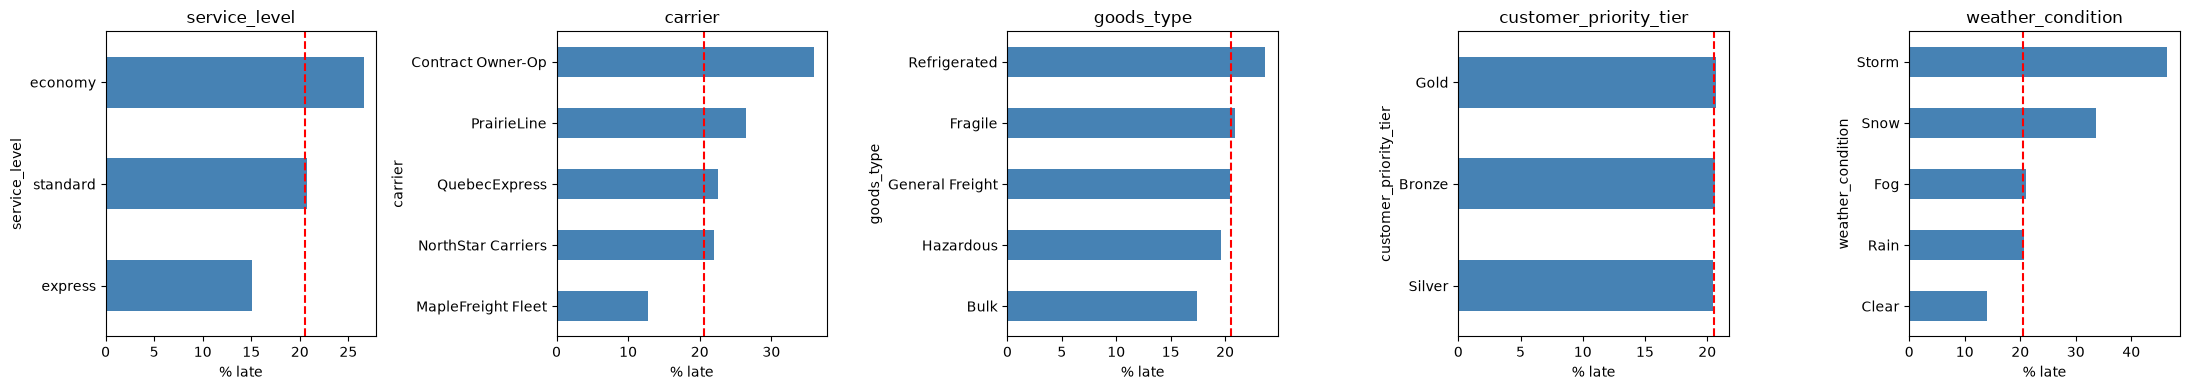

service_level
economy     26.6
standard    20.7
express     15.1
Name: delivered_late, dtype: float64 

carrier
Contract Owner-Op     36.0
PrairieLine           26.4
QuebecExpress         22.5
NorthStar Carriers    22.0
MapleFreight Fleet    12.8
Name: delivered_late, dtype: float64 

goods_type
Refrigerated       23.7
Fragile            20.9
General Freight    20.4
Hazardous          19.6
Bulk               17.4
Name: delivered_late, dtype: float64 

customer_priority_tier
Gold      20.7
Bronze    20.6
Silver    20.4
Name: delivered_late, dtype: float64 

weather_condition
Storm    46.5
Snow     33.6
Fog      21.0
Rain     20.7
Clear    14.1
Name: delivered_late, dtype: float64 



In [20]:
# Here we see the % of late shipments in each category (the red line is the overall % late)
cat_cols = ["service_level", "carrier", "goods_type", "customer_priority_tier", "weather_condition"]
overall_rate = df_clean["delivered_late"].mean() * 100

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, cat_cols):
    late_rate = df_clean.groupby(col)["delivered_late"].mean().mul(100).sort_values()
    late_rate.plot(kind="barh", ax=ax, color="steelblue")
    ax.axvline(overall_rate, color="red", linestyle="--")
    ax.set_title(col)
    ax.set_xlabel("% late")
plt.tight_layout()
plt.show()

for col in cat_cols:
    print(df_clean.groupby(col)["delivered_late"].mean().mul(100).round(1).sort_values(ascending=False), "\n")

**Findings:**
- **Weather is the strongest category:** Storm shipments are late **46.5%** of the time and Snow **33.6%**, vs only **14.1%** with Clear weather (overall: 20.6%). Bad weather more than triples the risk.
- **Carrier matters a lot:** Contract Owner-Op is late **36.0%** of the time, almost 3× more than MapleFreight Fleet (**12.8%**).
- **Service level:** economy is late more often (**26.6%**) than express (**15.1%**), which makes sense because express shipments get priority.
- **Goods type** has a small effect (Refrigerated 23.7% vs Bulk 17.4%).
- **Customer priority tier has no effect:** Gold, Silver and Bronze are all ≈ 20.5%. This feature probably won't help the model.

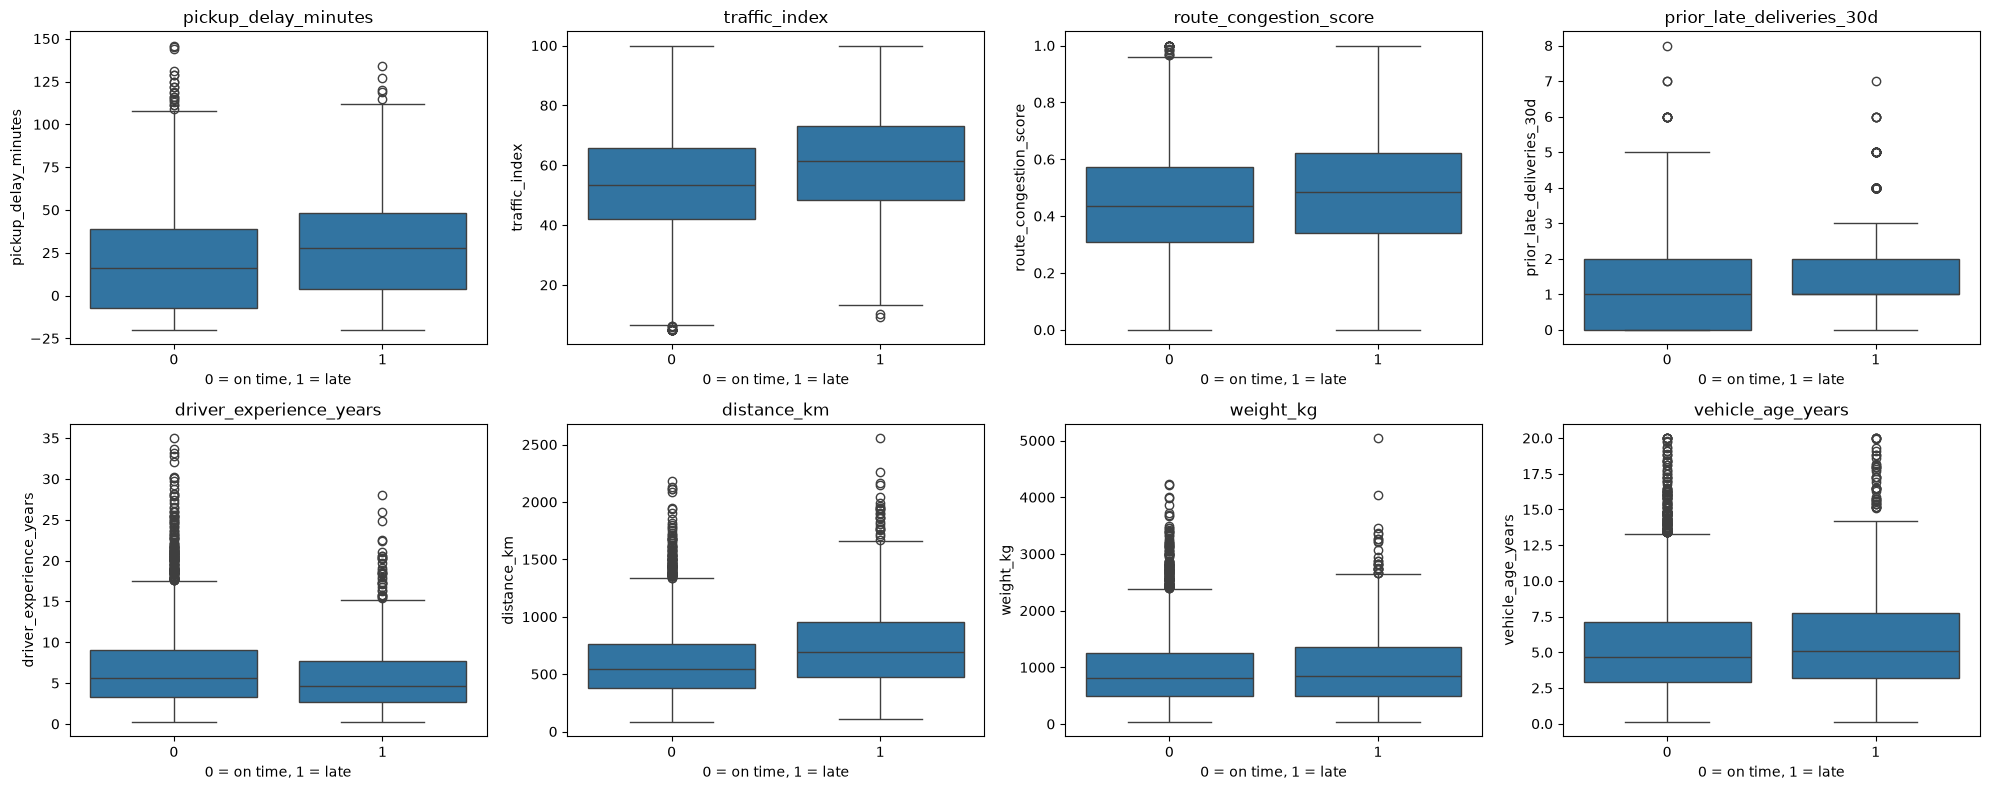

In [21]:
# Here we compare the numeric columns between on-time (0) and late (1) shipments
num_cols = ["pickup_delay_minutes", "traffic_index", "route_congestion_score", "prior_late_deliveries_30d",
            "driver_experience_years", "distance_km", "weight_kg", "vehicle_age_years"]

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=df_clean, x="delivered_late", y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("0 = on time, 1 = late")
plt.tight_layout()
plt.show()

**Findings:**
Comparing the medians of late (1) vs on-time (0) shipments:
- **Pickup delay:** late shipments had a median pickup delay of **28 min** vs **16 min** for on-time ones. A late start usually means a late arrival.
- **Traffic index:** 61.3 vs 53.4, and **route congestion:** 0.49 vs 0.44. More traffic → more delays.
- **Distance:** 689 km vs 548 km. Longer trips have more chances for something to go wrong.
- **Driver experience:** late shipments had less experienced drivers (4.7 vs 5.6 years).
- **Weight** (841 vs 818 kg) and **vehicle age** (5.1 vs 4.7 years) barely change. They are weak signals.
- The boxes overlap a lot for every feature, so **no single feature can predict a delay alone**. The model needs to combine them.

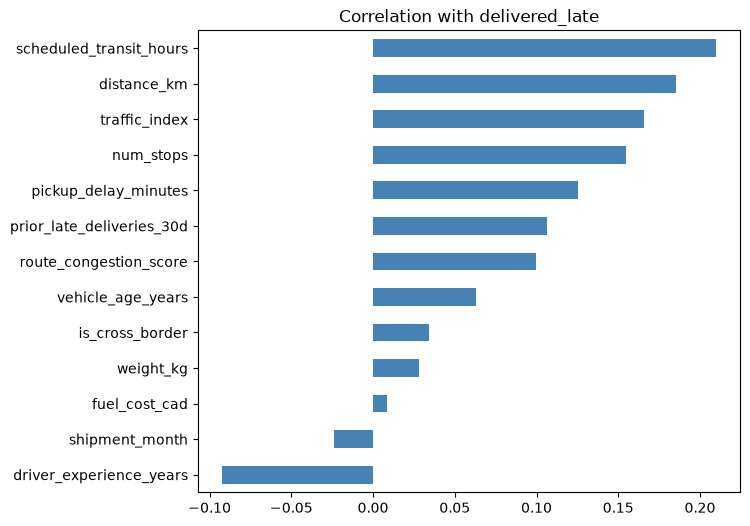

driver_experience_years     -0.092
shipment_month              -0.024
fuel_cost_cad                0.008
weight_kg                    0.028
is_cross_border              0.034
vehicle_age_years            0.063
route_congestion_score       0.100
prior_late_deliveries_30d    0.107
pickup_delay_minutes         0.125
num_stops                    0.155
traffic_index                0.166
distance_km                  0.185
scheduled_transit_hours      0.210
Name: delivered_late, dtype: float64


In [22]:
# Here we check the correlation of each numeric column with delivered_late
# We don't include actual_transit_hours because it is only known after delivery (leakage)
corr = (df_clean.select_dtypes("number")
        .drop(columns=["actual_transit_hours"])
        .corr()["delivered_late"]
        .drop("delivered_late")
        .sort_values())

corr.plot(kind="barh", figsize=(7, 6), color="steelblue")
plt.title("Correlation with delivered_late")
plt.show()
print(corr.round(3))

**Findings:**
- The strongest positive correlations with being late are `scheduled_transit_hours` (**0.21**), `distance_km` (0.19), `traffic_index` (0.17), `num_stops` (0.16) and `pickup_delay_minutes` (0.13).
- `driver_experience_years` is the only clear **negative** one (**-0.09**): more experience → fewer delays.
- `fuel_cost_cad` (0.008), `shipment_month` (-0.02) and `weight_kg` (0.03) are almost zero, so they are weak predictors.
- All correlations are **weak** (< 0.25). This confirms the boxplots: delays depend on a **combination** of factors (plus weather and carrier from the categorical analysis), so we need a model that combines many features.
- `actual_transit_hours` was excluded on purpose: it is only known after delivery (leakage).

**EDA summary:** the main delay risks are **bad weather (Storm/Snow), the Contract Owner-Op carrier, long routes with many stops, high traffic and late pickups**. Customer priority tier, fuel cost and weight have almost no effect.

## **Preprocessing & Feature Engineering**

In [23]:
# Feature engineering: we create 2 new columns based on what we found in the EDA
df_model = df_clean.copy()

# 1 if the weather is Storm or Snow (the most late shipments: 46.5% and 33.6%), 0 if not
df_model["is_bad_weather"] = df_model["weather_condition"].isin(["Storm", "Snow"]).astype(int)

# How many hours are planned for every 100 km (fewer hours = tighter schedule = more risk)
df_model["hours_per_100km"] = df_model["scheduled_transit_hours"] / df_model["distance_km"] * 100

df_model[["is_bad_weather", "hours_per_100km"]].describe()

,is_bad_weather,hours_per_100km
count,6000.000000,6000.000000
mean,0.191167,1.743575
std,0.393253,0.466612
min,0.000000,0.385208
25%,0.000000,1.469080
50%,0.000000,1.662335
75%,0.000000,1.924095
max,1.000000,6.981366


**Findings:**
We created 2 new features based on the EDA:
- `is_bad_weather`: **19.1%** of shipments travel in Storm or Snow, the two conditions with the highest late rates.
- `hours_per_100km`: on average **1.74 hours** are planned per 100 km (from 0.39 to 6.98). A low value means a tight schedule, which could increase the risk of being late.

In [24]:
from sklearn.model_selection import train_test_split

# We remove shipment_id (just a label), the target, and actual_transit_hours (leakage)
X = df_model.drop(columns=["shipment_id", "delivered_late", "actual_transit_hours"])
y = df_model["delivered_late"]

cat_features = ["origin_city", "destination_city", "carrier", "service_level",
                "goods_type", "customer_priority_tier", "weather_condition"]
num_features = [col for col in X.columns if col not in cat_features]

# 80% train / 20% test. stratify keeps the same 20.6% late in both
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Late rate train:", round(y_train.mean()*100, 1), "%  test:", round(y_test.mean()*100, 1), "%")

Train: (4800, 22)  Test: (1200, 22)
Late rate train: 20.6 %  test: 20.6 %


**Findings:**
- We dropped `shipment_id` (just a label, no predictive meaning) and `actual_transit_hours` (**leakage**: only known after delivery), and separated the target `delivered_late`.
- We use **22 features**: 7 categorical and 15 numeric (including the 2 new ones).
- Split 80/20: **4,800 train / 1,200 test**. Thanks to `stratify=y`, both sets keep exactly **20.6% late**, so the test set is a fair copy of reality.

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numeric columns: fill empty values with the median, then scale them
# Text columns: fill empty values with the most common value, then one-hot encode them
# Because this is inside the pipeline, it only learns from the training data (no leakage)
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
])

**Findings:**
We built a preprocessing pipeline so every model gets the same steps:
- **Numeric features:** missing values filled with the **median** (it is not affected much by extreme values), then scaled with `StandardScaler` so all features have a similar range.
- **Categorical features:** missing values (e.g. the 150 in `weather_condition`) filled with the **most frequent** value, then **one-hot encoded**. `handle_unknown="ignore"` prevents a crash if a new category appears in production (e.g. "STANDARD").
- Because the imputers are **inside** the pipeline, they learn only from the training data, so there is **no leakage** from the test set. The same pipeline will be applied to new shipments before sending Slack alerts.

## **Baseline Model: Logistic Regression**

              precision    recall  f1-score   support

     On time      0.852     0.963     0.904       953
        Late      0.715     0.356     0.476       247

    accuracy                          0.838      1200
   macro avg      0.784     0.660     0.690      1200
weighted avg      0.824     0.838     0.816      1200



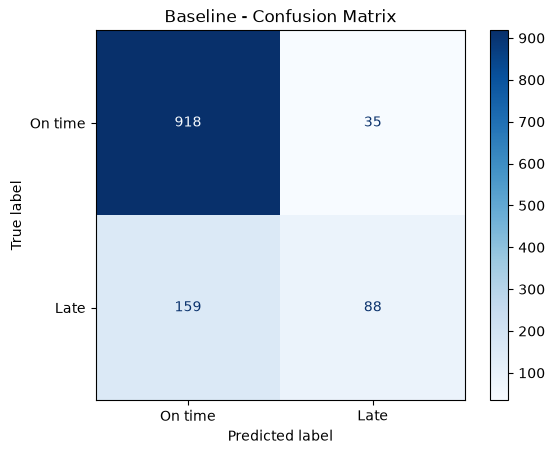

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Baseline: a simple Logistic Regression without handling the imbalance (to compare later)
baseline = Pipeline([("prep", preprocessor),
                     ("model", LogisticRegression(max_iter=1000))])
baseline.fit(X_train, y_train)
y_pred_base = baseline.predict(X_test)

print(classification_report(y_test, y_pred_base, target_names=["On time", "Late"], digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_base, display_labels=["On time", "Late"], cmap="Blues")
plt.title("Baseline - Confusion Matrix")
plt.show()

**Findings:**
- The baseline has **83.8% accuracy**, but that number is misleading: it only catches **88 of 247** late shipments (**recall 35.6%**). **159 late shipments are missed.**
- When it says "late", it's right 71.5% of the time (precision), but it says "late" too rarely.
- This is the imbalance problem from Step 1: the model learned that "on time" is almost always a safe answer. For dispatch, a missed late shipment means an unhappy customer, so this baseline isn't good enough.

## **Improved Model & Imbalance Handling**

In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# class_weight="balanced" gives the late shipments about 4x more weight,
# because there are about 4x fewer of them (20.6% vs 79.4%)
lr_balanced = Pipeline([("prep", preprocessor),
                        ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))])

rf_balanced = Pipeline([("prep", preprocessor),
                        ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                         class_weight="balanced", random_state=42, n_jobs=-1))])

lr_balanced.fit(X_train, y_train)
rf_balanced.fit(X_train, y_train)

# Here we compare the 3 models on the same test set
results = []
for name, model in [("Baseline LR", baseline), ("LR balanced", lr_balanced), ("Random Forest balanced", rf_balanced)]:
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    results.append({"Model": name,
                    "Precision (late)": round(precision_score(y_test, y_pred), 3),
                    "Recall (late)": round(recall_score(y_test, y_pred), 3),
                    "F1 (late)": round(f1_score(y_test, y_pred), 3),
                    "ROC-AUC": round(roc_auc_score(y_test, y_proba), 3)})

pd.DataFrame(results)

,Model,Precision (late),Recall (late),F1 (late),ROC-AUC
0,Baseline LR,0.715,0.356,0.476,0.820
1,LR balanced,0.426,0.729,0.537,0.822
2,Random Forest balanced,0.498,0.603,0.546,0.811


**Findings:**
- Handling the imbalance with `class_weight="balanced"` made a big difference in **recall**: from **35.6%** (baseline) to **72.9%** (LR balanced) and **60.3%** (Random Forest balanced).
- The cost: precision dropped (71.5% → 42.6% / 49.8%), so there are more false alarms. This is the normal **precision vs recall trade-off**.
- **ROC-AUC is similar for all models (~0.81–0.82)**, which means they rank shipments by risk equally well. The difference is mainly **where the cut-off is**, which we tune in the next step.
- **We choose the Random Forest balanced** because it has the **best F1 (0.546)**, the best balance between catching late shipments and avoiding false alarms. It can also capture combinations of factors (e.g. Storm + Contract Owner-Op), and it gives feature importances for explainability.

              precision    recall  f1-score   support

     On time      0.891     0.843     0.866       953
        Late      0.498     0.603     0.546       247

    accuracy                          0.793      1200
   macro avg      0.695     0.723     0.706      1200
weighted avg      0.810     0.793     0.800      1200



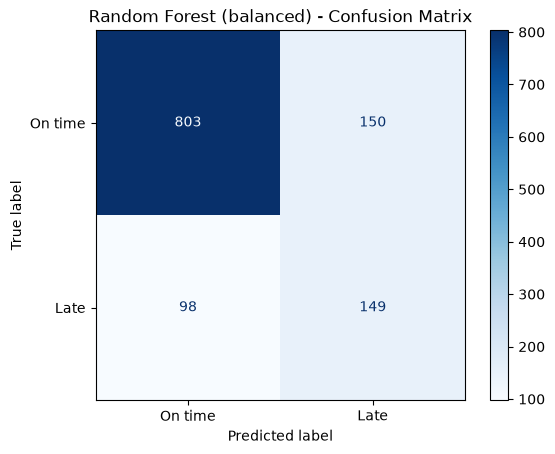

In [28]:
# Chosen model: Random Forest balanced (best F1, and it can learn combinations like weather + carrier)
y_pred_rf = rf_balanced.predict(X_test)
print(classification_report(y_test, y_pred_rf, target_names=["On time", "Late"], digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=["On time", "Late"], cmap="Blues")
plt.title("Random Forest (balanced) - Confusion Matrix")
plt.show()

**Findings:**
- The Random Forest catches **149 of 247** late shipments (**recall 60.3%**), vs only 88 with the baseline: **61 more late shipments detected**.
- It raises **150 false alarms** (on-time shipments flagged as late), vs 35 for the baseline. Precision is 49.8%: about **1 of every 2 alerts is a real delay**.
- Accuracy dropped from 83.8% to 79.3%, but that's expected and acceptable: **accuracy is not our goal**, catching late shipments is.

## **Threshold Selection**

In [29]:
# The model gives a probability of being late. The threshold decides when we send an alert.
# The default is 0.5, so here we test other values to find the best one for dispatch.
y_proba_rf = rf_balanced.predict_proba(X_test)[:, 1]

rows = []
for t in np.arange(0.20, 0.75, 0.05):
    y_pred_t = (y_proba_rf >= t).astype(int)
    rows.append({"Threshold": round(t, 2),
                 "Precision": round(precision_score(y_test, y_pred_t), 3),
                 "Recall": round(recall_score(y_test, y_pred_t), 3),
                 "F1": round(f1_score(y_test, y_pred_t), 3),
                 "Alerts sent": int(y_pred_t.sum())})
threshold_table = pd.DataFrame(rows)
threshold_table

,Threshold,Precision,Recall,F1,Alerts sent
0,0.20,0.242,0.972,0.388,991
1,0.25,0.271,0.943,0.421,861
2,0.30,0.303,0.923,0.456,752
3,0.35,0.335,0.846,0.480,624
4,0.40,0.403,0.789,0.534,484
5,0.45,0.467,0.717,0.565,379
6,0.50,0.498,0.603,0.546,299
7,0.55,0.543,0.462,0.499,210
8,0.60,0.624,0.356,0.454,141
9,0.65,0.726,0.247,0.369,84


**Findings:**
- A **low threshold** (0.30) catches 92% of late shipments but sends **752 alerts**, and only 30% of them are real. Dispatch would get too many alerts and start ignoring them.
- A **high threshold** (0.60) gives more precise alerts (62%) but misses almost **2 of every 3** late shipments.
- The **best F1 is at 0.45 (0.565)**: recall **71.7%**, precision **46.7%**, 379 alerts.

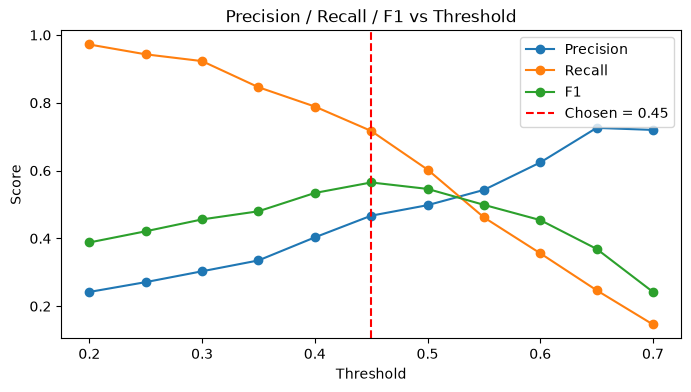

              precision    recall  f1-score   support

     On time      0.915     0.788     0.847       953
        Late      0.467     0.717     0.565       247

    accuracy                          0.773      1200
   macro avg      0.691     0.752     0.706      1200
weighted avg      0.823     0.773     0.789      1200



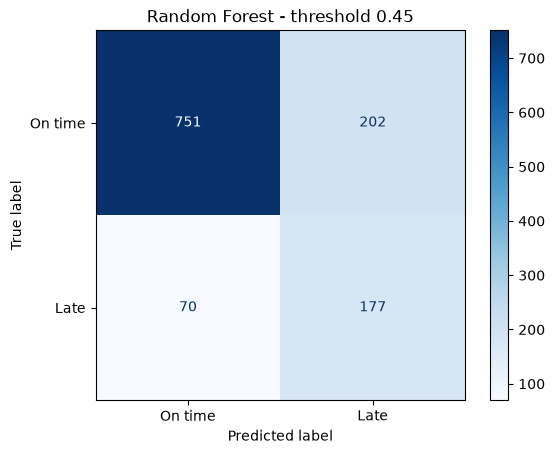

In [30]:
# Here we plot precision, recall and F1 for each threshold
plt.figure(figsize=(8, 4))
plt.plot(threshold_table["Threshold"], threshold_table["Precision"], marker="o", label="Precision")
plt.plot(threshold_table["Threshold"], threshold_table["Recall"], marker="o", label="Recall")
plt.plot(threshold_table["Threshold"], threshold_table["F1"], marker="o", label="F1")
THRESHOLD = 0.45
plt.axvline(THRESHOLD, color="red", linestyle="--", label=f"Chosen = {THRESHOLD}")
plt.xlabel("Threshold"); plt.ylabel("Score"); plt.title("Precision / Recall / F1 vs Threshold")
plt.legend(); plt.show()

# Results with the threshold we chose
y_pred_final = (y_proba_rf >= THRESHOLD).astype(int)
print(classification_report(y_test, y_pred_final, target_names=["On time", "Late"], digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_final, display_labels=["On time", "Late"], cmap="Blues")
plt.title(f"Random Forest - threshold {THRESHOLD}")
plt.show()

**Findings: chosen threshold = 0.45 (and why)**
- With 0.45 the model catches **177 of 247** late shipments (**71.7%**), vs 149 with the default 0.5 and only 88 with the baseline.
- It sends **202 false alarms**, so about **1 in 2 alerts is a real delay** (precision 46.7%).
- **Why 0.45:** it has the **best F1**, and for dispatch a **missed delay costs more** (unhappy customer, no time to react) than a **false alarm** (a dispatcher checks the shipment and sees it's fine). We still keep alerts manageable (~32% of shipments) so dispatch doesn't get too many alerts.
- If MapleFreight wants to catch more delays and has more dispatch staff, the threshold can be lowered to 0.40 (recall 79%).

## **Explainability: Which features drive the predictions?**

In [ ]:
from sklearn.inspection import permutation_importance

# Permutation importance: we mix up one column at a time and see how much the F1 goes down.
# If F1 goes down a lot, the model really needs that column.
perm = permutation_importance(rf_balanced, X_test, y_test, scoring="f1", n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

importance.plot(kind="barh", figsize=(8, 7), color="steelblue")
plt.title("Permutation importance (drop in F1 when the feature is shuffled)")
plt.show()
print(importance.sort_values(ascending=False).round(4).head(10))

**Findings:**
- The features the model relies on most are **`traffic_index`**, **`carrier`** and **`is_bad_weather`** (our engineered feature is the 3rd most important ✅), followed by `scheduled_transit_hours`, `num_stops`, `pickup_delay_minutes` and `driver_experience_years`.
- This **matches the EDA**: traffic, carrier (Contract Owner-Op 36% late), bad weather (Storm 46.5%), long routes and late pickups were the main risks.
- Features like `fuel_cost_cad`, `weight_kg`, `goods_type` and `customer_priority_tier` have ~0 or slightly negative importance: shuffling them doesn't hurt the model, so they add almost no information.
- **For dispatch:** an alert can be explained in simple terms, e.g. "high traffic + Contract Owner-Op + storm", so dispatch can understand why each alert was sent.

## **Slack Alert Integration**

In [ ]:
import os
import requests
from dotenv import load_dotenv

# The webhook URL works like a password, so it is saved in .env (ignored by git) and never in the code or the output
load_dotenv()
SLACK_WEBHOOK_URL = os.getenv("SLACK_WEBHOOK_URL")
print("Webhook loaded:", SLACK_WEBHOOK_URL is not None)   # prints True/False only, never the URL

Webhook loaded: True


**Findings:**
The webhook was loaded from `.env` (`True`). The URL itself is **never printed**, because it works like a password: anyone who has it can post messages in #dispatch-alerts. `.env` is listed in `.gitignore`, and the repository only contains `.env.example` with a fake value.

In [ ]:
# We use the test set as the "in-transit" shipments (the model has never seen them)
in_transit = df_model.loc[X_test.index, ["shipment_id", "origin_city", "destination_city", "carrier", "weather_condition"]].copy()
in_transit["weather_condition"] = in_transit["weather_condition"].fillna("Unknown")
in_transit["late_risk"] = y_proba_rf

# Shipments with risk above the threshold, sorted from highest to lowest risk
at_risk = in_transit[in_transit["late_risk"] >= THRESHOLD].sort_values("late_risk", ascending=False)
top5 = at_risk.head(5)

lines = [f"• *{r.shipment_id}*: {r.origin_city} → {r.destination_city} | {r.carrier} | {r.weather_condition} | risk {r.late_risk:.0%}"
         for r in top5.itertuples()]
message = (f":rotating_light: *MapleFreight Delay Alert*\n"
           f"*{len(at_risk)}* in-transit shipments are at risk of arriving late (risk ≥ {THRESHOLD:.0%}).\n"
           f"*Top 5 highest risk:*\n" + "\n".join(lines) +
           "\n_Action: contact the carrier, update the customer ETA, or reroute if possible._")
print(message)

# Send the message to #dispatch-alerts. If there is an error, we only print the error type, so the URL never shows up
try:
    response = requests.post(SLACK_WEBHOOK_URL, json={"text": message}, timeout=10)
    print("Slack response:", response.status_code, response.text)   # 200 ok = sent
except Exception as e:
    print("Could not send the alert:", type(e).__name__)

:rotating_light: *MapleFreight Delay Alert*
*379* in-transit shipments are at risk of arriving late (risk ≥ 45%).
*Top 5 highest risk:*
• *SHP-105655*: Toronto ON → Calgary AB | NorthStar Carriers | Snow | risk 88%
• *SHP-103300*: Mississauga ON → Winnipeg MB | NorthStar Carriers | Snow | risk 87%
• *SHP-105400*: Toronto ON → Montreal QC | NorthStar Carriers | Snow | risk 84%
• *SHP-105511*: Toronto ON → Ottawa ON | NorthStar Carriers | Snow | risk 83%
• *SHP-103230*: Montreal QC → Regina SK | Contract Owner-Op | Snow | risk 82%
_Action: contact the carrier, update the customer ETA, or reroute if possible._
Slack response: 200 ok


**Findings:**
- The alert was sent successfully to **#dispatch-alerts** (Slack response `200 ok`). Screenshot: `screenshots/slack_alert.png`.
- **379** of the 1,200 in-transit shipments are above the 0.45 risk threshold. The message shows the **top 5 highest-risk shipments** (82–88% risk) so dispatch can act on the most urgent ones first.
- All 5 are travelling in **Snow**, and 4 of them are with **NorthStar Carriers**. This matches the explainability results: bad weather and carrier are among the strongest drivers of delays.
- Each line includes the shipment ID, route, carrier, weather and risk, so a dispatcher knows **who to call and why** without opening the notebook.

## **Recommendations**
1. **Act on the Slack alerts:** for every alert, dispatch should contact the carrier, update the customer's ETA and reroute if possible. Prioritize by risk %.
2. **Bad weather protocol:** Storm (46.5% late) and Snow (33.6%) shipments should get extra time in the schedule, and the customer should be contacted early.
3. **Review carrier performance:** Contract Owner-Op is late 36% of the time vs 12.8% for MapleFreight Fleet. Review their contracts, or move important shipments to MapleFreight's own fleet.
4. **Reduce pickup delays:** late shipments had a median pickup delay of 28 min vs 16 min. Better pickup planning is an easy way to reduce delays.
5. **Improve data quality at the source:** standardize `service_level` values (dropdown instead of free text), enforce kg as the weight unit, add a record timestamp (to resolve duplicate IDs), and validate `distance_km` against real route distances.
6. **Monitor and retrain:** track precision/recall of the alerts every month and retrain the model with new data. Adjust the threshold (e.g. 0.40) if dispatch has capacity for more alerts.

**Limitations:** `distance_km` doesn't always match real distances, the conflicting duplicate ID was resolved with an assumption ("keep last"), and the test set is used to simulate in-transit shipments, so the model should be tested with real live data before using it in production.